In [1]:
#Importing all the neceassary libraries
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd 
import random
from sklearn.linear_model import LinearRegression
import seaborn as sns
from numpy import random

# Question 1

In [2]:
#Importing the data frame
TB_df = pd.read_csv("/Users/ahmadeblagh/Desktop/Year 3/Term 2 /Uncertainty Analysis/CW/TB_demographics.csv")

In [3]:
TB_df.shape

(3047, 19)

In [4]:
TB_df

,TARGET_residualsRatePerCapita,incidenceRatePerCapita,popEst2015,MarriedPerCapita,NoHS18_24PerCapita,HS18_24PerCapita,BachDeg18_24PerCapita,HS25_OverPerCapita,BachDeg25_OverPerCapita,Employed16_OverPerCapita,Unemployed16_OverPerCapita,PrivateCoveragePerCapita,EmpPrivCoveragePerCapita,PublicCoveragePerCapita,PublicCoverageAlonePerCapita,MarriedHouseholdsPerCapita,avgResidualsPerCapitaPerYear,povertyPerCapita,AvgHouseholdSizePerCapita
0,164.9,489.800000,260131,52500,11500,39500,6900,23200,19600,51900.00000,8000,75100,41600,32900,14000,52856.07588,180.293775,11200,0.976431
1,161.3,411.600000,43269,44500,6100,22400,7500,26000,22700,55900.00000,7800,70200,43600,31100,15300,45372.50044,161.778641,18600,5.408029
2,174.7,349.700000,21026,54200,24000,36600,9500,29000,16000,45900.00000,7000,63700,34900,42100,21100,54444.86837,237.800818,14600,12.460763
3,194.8,430.400000,75882,52700,20200,41200,2500,31600,9300,48300.00000,12100,58400,35000,45300,25000,51021.51448,266.202788,17100,3.320946
4,144.4,350.100000,10321,57800,14900,43000,2000,33400,15000,48200.00000,4800,61600,35100,44000,22700,54027.45995,251.913574,12500,22.672222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3042,149.6,453.549422,6343,51000,20900,27900,8400,32200,15200,51700.00000,4300,78300,44600,31700,13200,51063.82979,236.481160,12400,32.792054
3043,150.1,453.549422,37118,52600,26700,33900,3800,23100,12400,70100.00000,4600,64500,48600,28800,17700,52007.93651,115.846759,18800,7.812921
3044,153.9,453.549422,34536,54800,19700,44500,2500,23000,12800,64800.00000,6400,62000,47800,26600,16800,55153.94913,133.194348,15000,8.802409
3045,175.0,453.549422,25609,58800,10900,37200,4100,36100,14400,54152.64249,6900,75900,49600,29500,14000,58484.23194,203.053614,13300,9.996486


In [5]:
TB_df['TARGET_residualsRatePerCapita']

0       164.9
1       161.3
2       174.7
3       194.8
4       144.4
        ...  
3042    149.6
3043    150.1
3044    153.9
3045    175.0
3046    213.6
Name: TARGET_residualsRatePerCapita, Length: 3047, dtype: float64

In [6]:
TB_df.iloc[0:301,0:10]

,TARGET_residualsRatePerCapita,incidenceRatePerCapita,popEst2015,MarriedPerCapita,NoHS18_24PerCapita,HS18_24PerCapita,BachDeg18_24PerCapita,HS25_OverPerCapita,BachDeg25_OverPerCapita,Employed16_OverPerCapita
0,164.9,489.8,260131,52500,11500,39500,6900,23200,19600,51900.0
1,161.3,411.6,43269,44500,6100,22400,7500,26000,22700,55900.0
2,174.7,349.7,21026,54200,24000,36600,9500,29000,16000,45900.0
3,194.8,430.4,75882,52700,20200,41200,2500,31600,9300,48300.0
4,144.4,350.1,10321,57800,14900,43000,2000,33400,15000,48200.0
...,...,...,...,...,...,...,...,...,...,...
296,194.6,518.4,71122,47500,20800,38900,4800,32100,9900,45100.0
297,143.5,462.0,80593,59100,14700,43000,4700,23300,20600,48100.0
298,154.9,480.9,30466,53700,25200,27100,8100,23200,21500,43600.0
299,152.7,464.2,2117125,49500,12200,23100,19400,16500,29600,64900.0


In [7]:
TB_df.loc[(TB_df["incidenceRatePerCapita"]>= 300)& (TB_df["TARGET_residualsRatePerCapita"]>= 300)]

,TARGET_residualsRatePerCapita,incidenceRatePerCapita,popEst2015,MarriedPerCapita,NoHS18_24PerCapita,HS18_24PerCapita,BachDeg18_24PerCapita,HS25_OverPerCapita,BachDeg25_OverPerCapita,Employed16_OverPerCapita,Unemployed16_OverPerCapita,PrivateCoveragePerCapita,EmpPrivCoveragePerCapita,PublicCoveragePerCapita,PublicCoverageAlonePerCapita,MarriedHouseholdsPerCapita,avgResidualsPerCapitaPerYear,povertyPerCapita,AvgHouseholdSizePerCapita
1489,362.8,1206.9,15234,36400,27000,45100,0,37400,5500,54152.64249,11700,59600,41000,35800,22500,50012.87664,400.420113,24300,16.935802


In [8]:
#Conducting an outlier removal strategy using IQR method

def IQR_bounds(column):
    sorted(column) #Sorting the column 
    Quar_1, Quar_3 = np.percentile(column, [25,75])
    IQR = Quar_3 - Quar_1
    low_bound = Quar_1 - (1.5*IQR)
    up_bound = Quar_3 + (1.5*IQR)
    return low_bound, up_bound
    


In [9]:
low,up = IQR_bounds(TB_df['TARGET_residualsRatePerCapita'])

In [10]:
TB_df[(TB_df["TARGET_residualsRatePerCapita"]>=up)| (TB_df["TARGET_residualsRatePerCapita"]<=low) ]

,TARGET_residualsRatePerCapita,incidenceRatePerCapita,popEst2015,MarriedPerCapita,NoHS18_24PerCapita,HS18_24PerCapita,BachDeg18_24PerCapita,HS25_OverPerCapita,BachDeg25_OverPerCapita,Employed16_OverPerCapita,Unemployed16_OverPerCapita,PrivateCoveragePerCapita,EmpPrivCoveragePerCapita,PublicCoveragePerCapita,PublicCoverageAlonePerCapita,MarriedHouseholdsPerCapita,avgResidualsPerCapitaPerYear,povertyPerCapita,AvgHouseholdSizePerCapita
72,259.5,511.900000,8755,54100,10400,54600,2800,43000,5300,40200.0,14800,45100,28200,53300,35400,48726.52431,376.927470,26100,26.042262
115,262.1,453.549422,829,44300,1200,62700,0,43200,12600,46000.0,11900,56500,34900,37100,16500,40579.71014,482.509047,14000,283.474065
121,254.3,453.549422,4478,41800,6100,42300,0,31200,6800,48100.0,15400,58100,36400,43200,21600,34422.11055,446.627959,19000,0.502456
463,93.8,330.600000,2450,64500,11200,34600,13100,34300,18600,63500.0,700,83400,43100,27200,6000,58371.87789,163.265306,8300,84.489796
473,104.8,336.100000,2417,72300,21900,49100,3000,32600,16100,67000.0,900,76100,38100,33600,14200,65129.15129,165.494415,14100,92.676872
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2617,259.5,570.600000,7259,49700,9200,53900,2400,38500,5600,34400.0,9700,39300,23900,57400,40200,45305.00343,316.848051,36200,33.751205
2725,277.6,499.300000,9846,35900,24100,52100,1000,41300,10300,53400.0,16500,35800,27400,42400,33700,38324.78632,172.658948,26100,33.109892
2726,256.9,501.100000,9687,46700,16100,52000,3500,36800,10400,73400.0,9300,64100,54100,20200,12400,38073.39450,123.877361,11500,33.859812
2756,247.3,497.900000,17896,34500,24200,43600,3800,39800,8000,41400.0,14900,53400,33500,46800,26200,38433.82929,307.331247,27800,14.696021


In [11]:
df = TB_df.copy()

In [12]:
column = df.columns.values.tolist()

In [13]:
tot_row,tot_col = df.shape

In [14]:
for col in range(tot_col):
    low, up = IQR_bounds(TB_df[column[col]])
    outlier_rows = df[(df[column[col]]>=up) | (df[column[col]]<=low)].index
    df.drop(outlier_rows,0,inplace = True)

In [15]:
df

,TARGET_residualsRatePerCapita,incidenceRatePerCapita,popEst2015,MarriedPerCapita,NoHS18_24PerCapita,HS18_24PerCapita,BachDeg18_24PerCapita,HS25_OverPerCapita,BachDeg25_OverPerCapita,Employed16_OverPerCapita,Unemployed16_OverPerCapita,PrivateCoveragePerCapita,EmpPrivCoveragePerCapita,PublicCoveragePerCapita,PublicCoverageAlonePerCapita,MarriedHouseholdsPerCapita,avgResidualsPerCapitaPerYear,povertyPerCapita,AvgHouseholdSizePerCapita
1,161.3,411.600000,43269,44500,6100,22400,7500,26000,22700,55900.00000,7800,70200,43600,31100,15300,45372.50044,161.778641,18600,5.408029
2,174.7,349.700000,21026,54200,24000,36600,9500,29000,16000,45900.00000,7000,63700,34900,42100,21100,54444.86837,237.800818,14600,12.460763
3,194.8,430.400000,75882,52700,20200,41200,2500,31600,9300,48300.00000,12100,58400,35000,45300,25000,51021.51448,266.202788,17100,3.320946
4,144.4,350.100000,10321,57800,14900,43000,2000,33400,15000,48200.00000,4800,61600,35100,44000,22700,54027.45995,251.913574,12500,22.672222
5,176.0,505.400000,61023,50400,29900,35100,4500,30400,11900,44100.00000,12900,60000,32600,43200,20200,51220.35959,249.086410,15600,4.227914
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3042,149.6,453.549422,6343,51000,20900,27900,8400,32200,15200,51700.00000,4300,78300,44600,31700,13200,51063.82979,236.481160,12400,32.792054
3043,150.1,453.549422,37118,52600,26700,33900,3800,23100,12400,70100.00000,4600,64500,48600,28800,17700,52007.93651,115.846759,18800,7.812921
3044,153.9,453.549422,34536,54800,19700,44500,2500,23000,12800,64800.00000,6400,62000,47800,26600,16800,55153.94913,133.194348,15000,8.802409
3045,175.0,453.549422,25609,58800,10900,37200,4100,36100,14400,54152.64249,6900,75900,49600,29500,14000,58484.23194,203.053614,13300,9.996486


In [16]:
stats = df.describe()

In [17]:
stats

,TARGET_residualsRatePerCapita,incidenceRatePerCapita,popEst2015,MarriedPerCapita,NoHS18_24PerCapita,HS18_24PerCapita,BachDeg18_24PerCapita,HS25_OverPerCapita,BachDeg25_OverPerCapita,Employed16_OverPerCapita,Unemployed16_OverPerCapita,PrivateCoveragePerCapita,EmpPrivCoveragePerCapita,PublicCoveragePerCapita,PublicCoverageAlonePerCapita,MarriedHouseholdsPerCapita,avgResidualsPerCapitaPerYear,povertyPerCapita,AvgHouseholdSizePerCapita
count,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000
mean,181.535805,451.515840,38208.721463,52478.585366,18021.804878,36013.414634,5376.292683,36598.634146,12060.439024,53823.027474,7763.951220,64329.219512,41182.536585,36910.146341,19439.365854,51893.403224,235.525254,16706.439024,12.304049
std,23.005097,42.927052,32914.779022,5480.915463,6791.438619,7963.586023,3008.511419,5964.407043,3983.093946,7106.515668,2830.607824,9249.439057,8299.059870,6752.082952,5163.669364,5123.101974,49.961339,5352.656324,10.067799
min,114.300000,330.500000,4470.000000,34900.000000,1200.000000,12200.000000,0.000000,17400.000000,3900.000000,32400.000000,900.000000,35800.000000,16300.000000,16100.000000,5900.000000,36879.860150,92.280110,5100.000000,0.018627
25%,165.700000,424.925000,14434.250000,49000.000000,13400.000000,30900.000000,3200.000000,32500.000000,9125.000000,48800.000000,5700.000000,57525.000000,35200.000000,32200.000000,15700.000000,48732.012263,204.294143,12600.000000,4.753775
50%,181.450000,453.549422,26517.500000,52900.000000,17600.000000,36200.000000,5000.000000,36500.000000,11500.000000,54100.000000,7600.000000,64400.000000,41100.000000,37200.000000,19200.000000,51953.765100,237.103945,16200.000000,9.229873
75%,196.900000,480.650000,50392.250000,56300.000000,22475.000000,41200.000000,7200.000000,40900.000000,14475.000000,58900.000000,9600.000000,71300.000000,46700.000000,41600.000000,23100.000000,55332.471437,268.405537,20200.000000,16.681663
max,245.200000,570.800000,153721.000000,68000.000000,37300.000000,57600.000000,15500.000000,52700.000000,25900.000000,73600.000000,15900.000000,87700.000000,66600.000000,56000.000000,34900.000000,66720.324020,385.645421,32700.000000,47.056200


In [18]:
df.kurtosis()

TARGET_residualsRatePerCapita   -0.181357
incidenceRatePerCapita          -0.005941
popEst2015                       1.734809
MarriedPerCapita                 0.037549
NoHS18_24PerCapita              -0.157475
HS18_24PerCapita                 0.034900
BachDeg18_24PerCapita            0.127086
HS25_OverPerCapita              -0.175415
BachDeg25_OverPerCapita          0.284263
Employed16_OverPerCapita        -0.322521
Unemployed16_OverPerCapita      -0.291329
PrivateCoveragePerCapita        -0.554271
EmpPrivCoveragePerCapita        -0.330440
PublicCoveragePerCapita         -0.251972
PublicCoverageAlonePerCapita    -0.375606
MarriedHouseholdsPerCapita       0.069707
avgResidualsPerCapitaPerYear     0.092739
povertyPerCapita                -0.310107
AvgHouseholdSizePerCapita        1.057854
dtype: float64

In [19]:
df.skew()

TARGET_residualsRatePerCapita    0.047702
incidenceRatePerCapita          -0.263712
popEst2015                       1.501126
MarriedPerCapita                -0.378838
NoHS18_24PerCapita               0.273618
HS18_24PerCapita                -0.125613
BachDeg18_24PerCapita            0.598839
HS25_OverPerCapita              -0.071965
BachDeg25_OverPerCapita          0.725855
Employed16_OverPerCapita        -0.026057
Unemployed16_OverPerCapita       0.246996
PrivateCoveragePerCapita        -0.087170
EmpPrivCoveragePerCapita         0.097537
PublicCoveragePerCapita         -0.103114
PublicCoverageAlonePerCapita     0.123121
MarriedHouseholdsPerCapita      -0.148381
avgResidualsPerCapitaPerYear    -0.082942
povertyPerCapita                 0.430171
AvgHouseholdSizePerCapita        1.263559
dtype: float64

In [20]:
stats.append([df.kurtosis(),df.skew()])

,TARGET_residualsRatePerCapita,incidenceRatePerCapita,popEst2015,MarriedPerCapita,NoHS18_24PerCapita,HS18_24PerCapita,BachDeg18_24PerCapita,HS25_OverPerCapita,BachDeg25_OverPerCapita,Employed16_OverPerCapita,Unemployed16_OverPerCapita,PrivateCoveragePerCapita,EmpPrivCoveragePerCapita,PublicCoveragePerCapita,PublicCoverageAlonePerCapita,MarriedHouseholdsPerCapita,avgResidualsPerCapitaPerYear,povertyPerCapita,AvgHouseholdSizePerCapita
count,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000,2050.000000
mean,181.535805,451.515840,38208.721463,52478.585366,18021.804878,36013.414634,5376.292683,36598.634146,12060.439024,53823.027474,7763.951220,64329.219512,41182.536585,36910.146341,19439.365854,51893.403224,235.525254,16706.439024,12.304049
std,23.005097,42.927052,32914.779022,5480.915463,6791.438619,7963.586023,3008.511419,5964.407043,3983.093946,7106.515668,2830.607824,9249.439057,8299.059870,6752.082952,5163.669364,5123.101974,49.961339,5352.656324,10.067799
min,114.300000,330.500000,4470.000000,34900.000000,1200.000000,12200.000000,0.000000,17400.000000,3900.000000,32400.000000,900.000000,35800.000000,16300.000000,16100.000000,5900.000000,36879.860150,92.280110,5100.000000,0.018627
25%,165.700000,424.925000,14434.250000,49000.000000,13400.000000,30900.000000,3200.000000,32500.000000,9125.000000,48800.000000,5700.000000,57525.000000,35200.000000,32200.000000,15700.000000,48732.012263,204.294143,12600.000000,4.753775
50%,181.450000,453.549422,26517.500000,52900.000000,17600.000000,36200.000000,5000.000000,36500.000000,11500.000000,54100.000000,7600.000000,64400.000000,41100.000000,37200.000000,19200.000000,51953.765100,237.103945,16200.000000,9.229873
75%,196.900000,480.650000,50392.250000,56300.000000,22475.000000,41200.000000,7200.000000,40900.000000,14475.000000,58900.000000,9600.000000,71300.000000,46700.000000,41600.000000,23100.000000,55332.471437,268.405537,20200.000000,16.681663
max,245.200000,570.800000,153721.000000,68000.000000,37300.000000,57600.000000,15500.000000,52700.000000,25900.000000,73600.000000,15900.000000,87700.000000,66600.000000,56000.000000,34900.000000,66720.324020,385.645421,32700.000000,47.056200
0,-0.181357,-0.005941,1.734809,0.037549,-0.157475,0.034900,0.127086,-0.175415,0.284263,-0.322521,-0.291329,-0.554271,-0.330440,-0.251972,-0.375606,0.069707,0.092739,-0.310107,1.057854
1,0.047702,-0.263712,1.501126,-0.378838,0.273618,-0.125613,0.598839,-0.071965,0.725855,-0.026057,0.246996,-0.087170,0.097537,-0.103114,0.123121,-0.148381,-0.082942,0.430171,1.263559


In [21]:
mean = stats.iloc[1][0]

In [22]:
mean

181.53580487804885

In [23]:
mode = df["Employed16_OverPerCapita"].mode()

# Question 2

In [24]:
#Generating the distributions for the systematic errors
np.random.seed(1234545)
b0 = np.random.uniform(0,1,2050)*(0.5/100)
np.random.seed(1234545)
b2 = np.random.normal(stats.iloc[1][2],(2/200)*stats.iloc[1][2],2050)
np.random.seed(1234545)
b7 = np.random.normal(stats.iloc[1][7],(1/100)*stats.iloc[1][7],2050)
np.random.seed(1234545)
b9 = np.random.triangular(stats.iloc[3][9],mode,stats.iloc[7][9],2050)*(0.25/100)
np.random.seed(1234545)
b10 = np.random.normal(stats.iloc[1][10],(1/100)*stats.iloc[1][10],2050)
np.random.seed(1234545)
b16 = np.random.uniform(stats.iloc[3][16],stats.iloc[3][16])*(4/100)
np.random.seed(1234545)
b17 = np.random.uniform(stats.iloc[3][17],stats.iloc[3][17])*(1.5/100)

(array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 array([76.        , 76.03333333, 76.06666667, 76.1       , 76.13333333,
        76.16666667, 76.2       , 76.23333333, 76.26666667, 76.3       ,
        76.33333333, 76.36666667, 76.4       , 76.43333333, 76.46666667,
        76.5       , 76.53333333, 76.56666667, 76.6       , 76.63333333,
        76.66666667, 76.7       , 76.73333333, 76.76666667, 76.8       ,
        76.83333333, 76.86666667, 76.9       , 76.93333333, 76.96666667,
        77.        ]),
 <BarContainer object of 30 artists>)

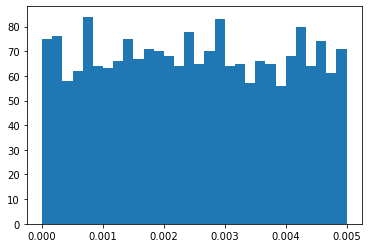

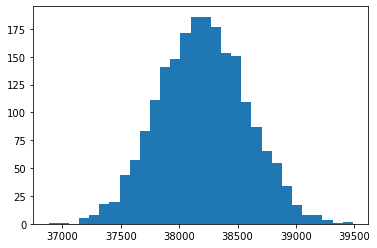

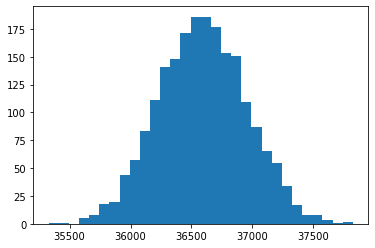

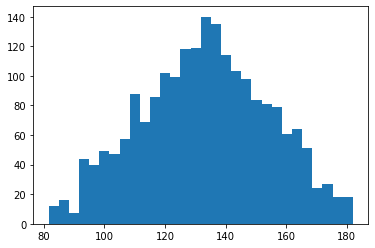

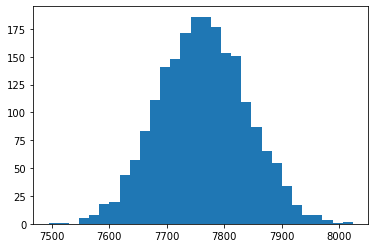

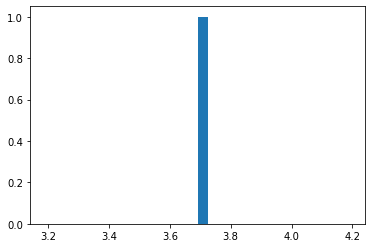

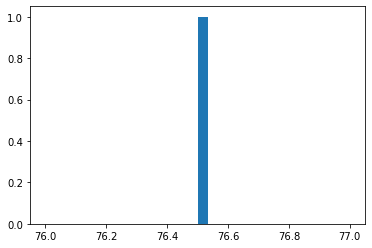

In [25]:
plt.hist(b0, bins = 30)
plt.figure()
plt.hist(b2, bins = 30)
plt.figure()
plt.hist(b7, bins = 30)
plt.figure()
plt.hist(b9, bins = 30)
plt.figure()
plt.hist(b10, bins = 30)
plt.figure()
plt.hist(b16, bins = 30)
plt.figure()
plt.hist(b17, bins = 30)

In [26]:
random.seed(1212321)
r = random.randint(0,2050)

## Trying to execute the model values with the random and systematic distribution

In [27]:
#Redoing the distribution by taking the mean to be zero
np.random.seed(1234545)
b0 = np.random.uniform(0,1,2050)*(0.5/200)
np.random.seed(1283917231)
b2 = np.random.normal(scale = 2/200, size = 2050)
np.random.seed(98127311)
b7 = np.random.normal(scale = (1/200), size = 2050)
np.random.seed(3748781)
b9 = np.random.triangular(-1,0,1, size = 2050)*(0.25/200)
np.random.seed(484738287)
b10 = np.random.normal( scale = (6/200),size = 2050)
np.random.seed(9274821)
b16 = np.random.uniform(0,1,2050)*(4/100)
np.random.seed(48737438)
b17 = np.random.uniform(0,1,2050)*(1.5/100)

In [28]:
b9

array([-2.89676302e-04, -3.36644615e-04, -3.52475991e-04, ...,
        9.45813311e-05,  7.06324791e-04,  2.74600020e-04])

(array([  6.,  24.,  53., 143., 360., 506., 609., 270.,  70.,   9.]),
 array([-1673.075633  , -1431.10921584, -1189.14279869,  -947.17638154,
         -705.20996439,  -463.24354724,  -221.27713009,    20.68928706,
          262.65570421,   504.62212136,   746.58853851]),
 <BarContainer object of 10 artists>)

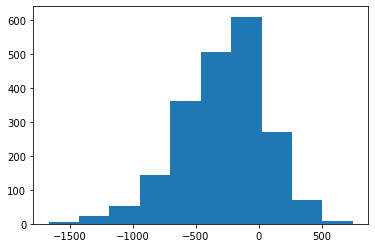

In [29]:
#input variable 2 recalculation
np.random.seed(12324432)
z2_b2 = (df["popEst2015"] + stats.iloc[2][2]*np.random.normal(size = 2050))*b2[r]
plt.hist(z2_b2)

(array([  7.,  64., 133., 284., 475., 506., 334., 172.,  56.,  19.]),
 array([-252.96392132, -232.16034502, -211.35676871, -190.55319241,
        -169.7496161 , -148.9460398 , -128.14246349, -107.33888719,
         -86.53531088,  -65.73173458,  -44.92815827]),
 <BarContainer object of 10 artists>)

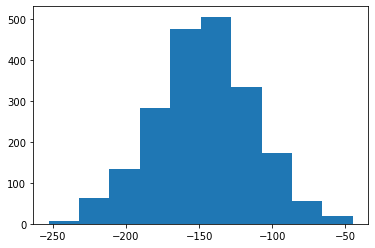

In [30]:
#input variable 7 recalculation
np.random.seed(12324432)
z7_b7 = (df["HS25_OverPerCapita"] + stats.iloc[2][7]*np.random.normal(size = 2050))*b7[r]
plt.hist(z7_b7)

(array([  1.,  33., 126., 289., 488., 498., 357., 181.,  65.,  12.]),
 array([ 3.40967344,  4.49934058,  5.58900773,  6.67867488,  7.76834202,
         8.85800917,  9.94767632, 11.03734346, 12.12701061, 13.21667776,
        14.30634491]),
 <BarContainer object of 10 artists>)

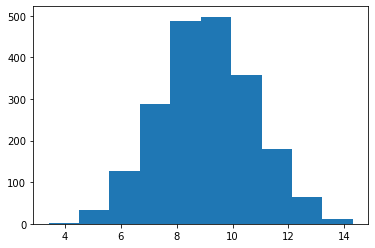

In [31]:
#input variable 9 recalculation
np.random.seed(12324432)
z9_b9 = (df["Employed16_OverPerCapita"] + stats.iloc[2][9]*np.random.normal(size = 2050))*b9[r]
plt.hist(z9_b9)

(array([ 10.,  62., 202., 414., 516., 436., 262., 117.,  26.,   5.]),
 array([-8.66230945, -3.51318468,  1.63594008,  6.78506484, 11.93418961,
        17.08331437, 22.23243913, 27.38156389, 32.53068866, 37.67981342,
        42.82893818]),
 <BarContainer object of 10 artists>)

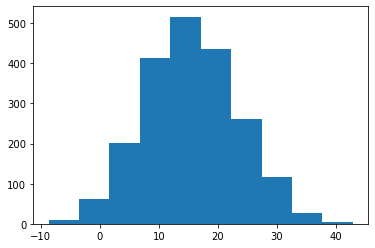

In [32]:
#input variable 10 recalculation
np.random.seed(12324432)
z10_b10 = (df["Unemployed16_OverPerCapita"] + stats.iloc[2][10]*np.random.normal(size = 2050))*b10[r]
plt.hist(z10_b10)

(array([ 22.,  86., 257., 463., 557., 411., 190.,  53.,  10.,   1.]),
 array([ 0.89152241,  2.8221936 ,  4.75286479,  6.68353598,  8.61420718,
        10.54487837, 12.47554956, 14.40622075, 16.33689194, 18.26756314,
        20.19823433]),
 <BarContainer object of 10 artists>)

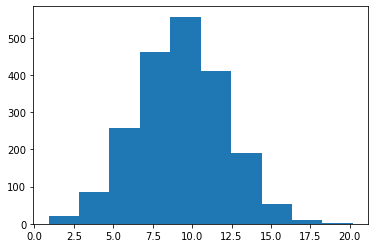

In [33]:
#input variable 16 recalculation
np.random.seed(12324432)
z16_b16 = (df["avgResidualsPerCapitaPerYear"] + stats.iloc[2][16]*np.random.normal(size = 2050))*b16[r]
plt.hist(z16_b16)

(array([ 19., 114., 265., 436., 491., 396., 211.,  83.,  29.,   6.]),
 array([-36.87000252,  10.55820426,  57.98641104, 105.41461782,
        152.84282461, 200.27103139, 247.69923817, 295.12744495,
        342.55565173, 389.98385852, 437.4120653 ]),
 <BarContainer object of 10 artists>)

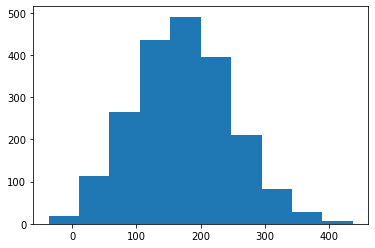

In [34]:
#input variable 17 recalculation
np.random.seed(12324432)
z17_b17 = (df["povertyPerCapita"] + stats.iloc[2][17]*np.random.normal(size = 2050))*b17[r]
plt.hist(z17_b17)

In [35]:
Y = b0 + z2_b2 + z7_b7 + z9_b9 + z10_b10 + z16_b16 + z17_b17

(array([  6.,  21.,  48., 104., 267., 469., 633., 390.,  99.,  13.]),
 array([-1.58189870e+03, -1.35599368e+03, -1.13008867e+03, -9.04183647e+02,
        -6.78278629e+02, -4.52373610e+02, -2.26468591e+02, -5.63572585e-01,
         2.25341446e+02,  4.51246465e+02,  6.77151483e+02]),
 <BarContainer object of 10 artists>)

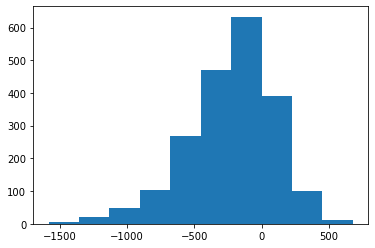

In [36]:
plt.hist(Y)

(array([ 16.,  62., 149., 312., 424., 451., 340., 188.,  77.,  31.]),
 array([114.3 , 127.39, 140.48, 153.57, 166.66, 179.75, 192.84, 205.93,
        219.02, 232.11, 245.2 ]),
 <BarContainer object of 10 artists>)

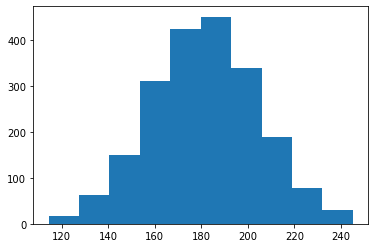

In [37]:
plt.hist(df["TARGET_residualsRatePerCapita"])

## Redoing by computing the coefficients 

In [38]:
X = df.drop("TARGET_residualsRatePerCapita",1)

In [39]:
X

,incidenceRatePerCapita,popEst2015,MarriedPerCapita,NoHS18_24PerCapita,HS18_24PerCapita,BachDeg18_24PerCapita,HS25_OverPerCapita,BachDeg25_OverPerCapita,Employed16_OverPerCapita,Unemployed16_OverPerCapita,PrivateCoveragePerCapita,EmpPrivCoveragePerCapita,PublicCoveragePerCapita,PublicCoverageAlonePerCapita,MarriedHouseholdsPerCapita,avgResidualsPerCapitaPerYear,povertyPerCapita,AvgHouseholdSizePerCapita
1,411.600000,43269,44500,6100,22400,7500,26000,22700,55900.00000,7800,70200,43600,31100,15300,45372.50044,161.778641,18600,5.408029
2,349.700000,21026,54200,24000,36600,9500,29000,16000,45900.00000,7000,63700,34900,42100,21100,54444.86837,237.800818,14600,12.460763
3,430.400000,75882,52700,20200,41200,2500,31600,9300,48300.00000,12100,58400,35000,45300,25000,51021.51448,266.202788,17100,3.320946
4,350.100000,10321,57800,14900,43000,2000,33400,15000,48200.00000,4800,61600,35100,44000,22700,54027.45995,251.913574,12500,22.672222
5,505.400000,61023,50400,29900,35100,4500,30400,11900,44100.00000,12900,60000,32600,43200,20200,51220.35959,249.086410,15600,4.227914
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3042,453.549422,6343,51000,20900,27900,8400,32200,15200,51700.00000,4300,78300,44600,31700,13200,51063.82979,236.481160,12400,32.792054
3043,453.549422,37118,52600,26700,33900,3800,23100,12400,70100.00000,4600,64500,48600,28800,17700,52007.93651,115.846759,18800,7.812921
3044,453.549422,34536,54800,19700,44500,2500,23000,12800,64800.00000,6400,62000,47800,26600,16800,55153.94913,133.194348,15000,8.802409
3045,453.549422,25609,58800,10900,37200,4100,36100,14400,54152.64249,6900,75900,49600,29500,14000,58484.23194,203.053614,13300,9.996486


In [40]:
y = df["TARGET_residualsRatePerCapita"]

In [41]:
reg = LinearRegression().fit(X, y)

In [42]:
cof = reg.coef_

In [43]:
cof

array([ 1.02048668e-01,  2.21368144e-05, -8.83264191e-04, -6.74657584e-05,
        2.35788890e-04, -1.47355857e-04, -1.04905952e-04, -7.65257720e-04,
       -1.42530480e-04,  1.15067991e-03,  6.42715857e-05, -8.04472267e-05,
       -4.64089232e-03,  4.22073705e-03,  8.41804074e-04,  4.53905946e-01,
        5.92997200e-04, -3.09570775e-01])

In [44]:
inter = reg.intercept_

In [45]:
X.columns[1:]

Index(['popEst2015', 'MarriedPerCapita', 'NoHS18_24PerCapita',
       'HS18_24PerCapita', 'BachDeg18_24PerCapita', 'HS25_OverPerCapita',
       'BachDeg25_OverPerCapita', 'Employed16_OverPerCapita',
       'Unemployed16_OverPerCapita', 'PrivateCoveragePerCapita',
       'EmpPrivCoveragePerCapita', 'PublicCoveragePerCapita',
       'PublicCoverageAlonePerCapita', 'MarriedHouseholdsPerCapita',
       'avgResidualsPerCapitaPerYear', 'povertyPerCapita',
       'AvgHouseholdSizePerCapita'],
      dtype='object')

## Recalculting the Y using the coefficients

In [46]:
Y = 0
#systematic errors 
b = [b0[r],0,b2[r],0,0,0,0,b7[r],0,b9[r],b10[r],0,0,0,0,0,b16[r],b17[r],0]

col_name = X.columns.values.tolist()

for col in range(tot_col-1):
    Y += (cof[col] + (b[col+1]*cof[col]))*X[col_name[col]]

Y += (inter + inter*b[0])



In [47]:
Y

1       151.841485
2       156.260697
3       195.896196
4       153.226585
5       183.220679
           ...    
3042    168.018971
3043    156.501461
3044    174.763253
3045    179.011635
3046    165.850087
Name: incidenceRatePerCapita, Length: 2050, dtype: float64

(array([  3.,  23.,  98., 320., 518., 534., 372., 148.,  32.,   2.]),
 array([111.72450349, 126.24241432, 140.76032515, 155.27823599,
        169.79614682, 184.31405765, 198.83196848, 213.34987931,
        227.86779015, 242.38570098, 256.90361181]),
 <BarContainer object of 10 artists>)

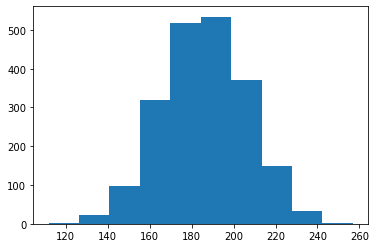

In [48]:
plt.hist(Y)

(array([ 16.,  62., 149., 312., 424., 451., 340., 188.,  77.,  31.]),
 array([114.3 , 127.39, 140.48, 153.57, 166.66, 179.75, 192.84, 205.93,
        219.02, 232.11, 245.2 ]),
 <BarContainer object of 10 artists>)

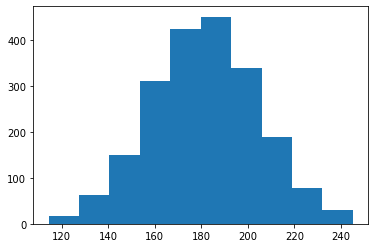

In [49]:
plt.hist(df["TARGET_residualsRatePerCapita"])

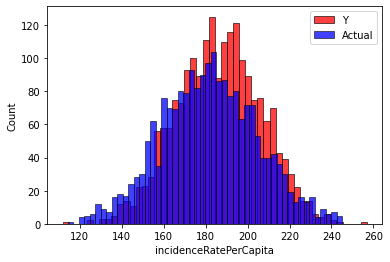

In [50]:
sns.histplot(Y, bins = 50, color = "red", label = "Y")
sns.histplot(df["TARGET_residualsRatePerCapita"], bins = 50, color = "blue", label = "Actual")
plt.legend()

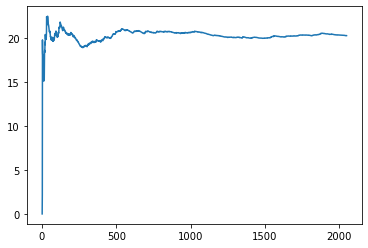

In [51]:
#Plotting the standard deviation
std = []

for i in range(len(Y)):
    ith_std = np.std(Y[:i])
    std.append(ith_std)

plt.plot(std)


## MCM that incorporates random errors

In [52]:
sigma = stats.iloc[2].drop("TARGET_residualsRatePerCapita")
mean = stats.iloc[1].drop("TARGET_residualsRatePerCapita")

In [53]:
mean

incidenceRatePerCapita            451.515840
popEst2015                      38208.721463
MarriedPerCapita                52478.585366
NoHS18_24PerCapita              18021.804878
HS18_24PerCapita                36013.414634
BachDeg18_24PerCapita            5376.292683
HS25_OverPerCapita              36598.634146
BachDeg25_OverPerCapita         12060.439024
Employed16_OverPerCapita        53823.027474
Unemployed16_OverPerCapita       7763.951220
PrivateCoveragePerCapita        64329.219512
EmpPrivCoveragePerCapita        41182.536585
PublicCoveragePerCapita         36910.146341
PublicCoverageAlonePerCapita    19439.365854
MarriedHouseholdsPerCapita      51893.403224
avgResidualsPerCapitaPerYear      235.525254
povertyPerCapita                16706.439024
AvgHouseholdSizePerCapita          12.304049
Name: mean, dtype: float64

In [54]:
# y = []
#systematic and random errors
b = [b0[r],0,b2[r],0,0,0,0,b7[r],0,b9[r],b10[r],0,0,0,0,0,b16[r],b17[r],0]

np.random.seed(189239812)

# for i in range(len(rand)):
#     rand = np.random.normal(size = 100000)
#     Y_val = 0
#     for col in range(tot_col-1):
#         Y_val += (cof[col] + (b[col+1]*cof[col]))*(mean[col_name[col]] + sigma[col]*rand[i])
#     Y_val += inter + inter*b[0]
#     y.append(Y_val)
    

    
y = 0
for col in range(tot_col-1):
    rand = np.random.normal(size = 100000)
    y += (cof[col] + (b[col+1]*cof[col]))*(mean[col_name[col]] + sigma[col]*rand)

y += inter + inter*b[0]

    
    

# col_name = X.columns.values.tolist()

# for col in range(tot_col-1):
#     Y += (cof[col] + (b[col+1]*cof[col]))*X[col_name[col]]

# Y += (inter + inter*b[0])


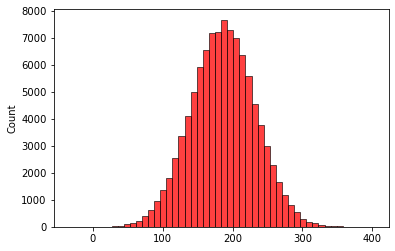

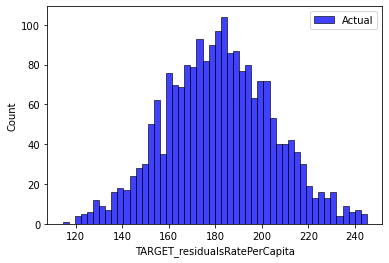

In [55]:
plt.figure()
sns.histplot(y, bins = 50, color = "red", label = "y")
plt.figure()
sns.histplot(df["TARGET_residualsRatePerCapita"], bins = 50, color = "blue", label = "Actual")
plt.legend()

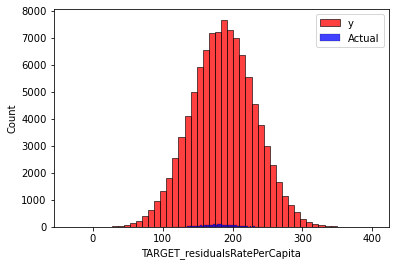

In [56]:
plt.figure()
sns.histplot(y, bins = 50, color = "red", label = "y")
sns.histplot(df["TARGET_residualsRatePerCapita"], bins = 50, color = "blue", label = "Actual")
plt.legend()

/opt/anaconda3/lib/python3.8/site-packages/numpy/core/_methods.py:261: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/lib/python3.8/site-packages/numpy/core/_methods.py:221: RuntimeWarning: invalid value encountered in true_divide
  arrmean = um.true_divide(arrmean, div, out=arrmean, casting='unsafe',
/opt/anaconda3/lib/python3.8/site-packages/numpy/core/_methods.py:253: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


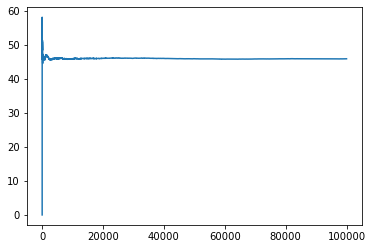

In [57]:
#Plotting the standard deviation
std = []

for i in range(len(y)):
    ith_std = np.std(y[1:i])
    std.append(ith_std)
    
plt.plot(std)

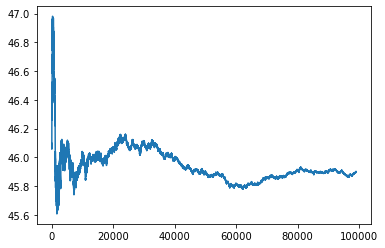

In [58]:
plt.plot(std[1000:])

## Adaptive Monte Carlo Method

In [59]:
# std = []
# count = 0
# for i in range(len(y)):
#     ith_std = np.std(y[1:i])
#     if 1-(np.std(y[:i+1]/np.std(y[:i]))) <= 0.004:
#         count += 1
#     else:
#         count = 0

#     if count >= 1000:
#         break
#     else:
#         std.append(ith_std)
    
exp = []
count = 0
for s in range(len(std)):
    if 1-(std[s+1]/std[s]) <= 0.004:
        count += 1
    else:
        count = 0

    if count >= 1000:
        break
    else:
        exp.append(std[s]*2)
    
    



<ipython-input-59-540feaabd8a6>:18: RuntimeWarning: divide by zero encountered in double_scalars
  if 1-(std[s+1]/std[s]) <= 0.004:


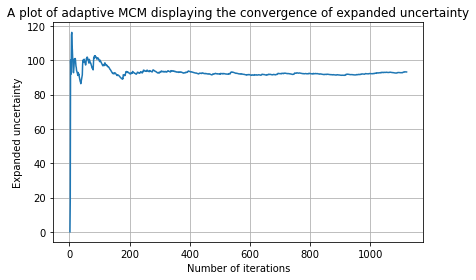

In [60]:
plt.plot(exp)
plt.title("A plot of adaptive MCM displaying the convergence of expanded uncertainty")
plt.ylabel("Expanded uncertainty")
plt.xlabel("Number of iterations")
plt.grid()
plt.tight_layout()

# Question 3 - Sensitivity Analysis 

In [93]:
#Everything in one cell

k = 25
p = 4
r = 10
delta = 2/3
B = np.ones((k+1,k))
B = np.tril(B,-1)
J = np.ones((k+1,k))
BMJ = 2*B - J

np.random.seed(123456789)
D = random.choice((-1,1) ,size = (k,1))
D = np.diagflat(D)

BmJtd = np.dot(BMJ,D)

BmJtDpJ = BmJtd + J

BmJtDpJtD2 = BmJtDpJ*(delta/2)

np.random.seed(123456789)
x_star = np.random.choice((0,(1-delta)), size = (1,k))

Jtx = J*x_star

JtxBmJtDpJtD2 = Jtx + BmJtDpJtD2

P = np.eye(k)

np.random.seed(123456789)
np.random.shuffle(P)


Bstar = np.dot(JtxBmJtDpJtD2,P)

Bstar = pd.DataFrame(Bstar, columns = ["Z1","Z2", "Z3", "Z4",
                                       "Z5","Z6","Z7","Z8","Z9","Z10","Z11","Z12","Z13","Z14","Z15",
                                       "Z16","Z17","Z18",
                                      "B0", "B2","B7","B9","B10","B16","B17"])

# Bstar = pd.DataFrame(Bstar)

In [105]:
Bstar

,Z1,Z2,Z3,Z4,Z5,Z6,Z7,Z8,Z9,Z10,...,Z16,Z17,Z18,B0,B2,B7,B9,B10,B16,B17
0,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.666667,0.666667,0.666667,0.333333,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.666667
1,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.666667,0.666667,0.000000,0.333333,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.666667
2,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.666667,0.666667,0.000000,0.333333,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,0.333333,0.000000,0.333333,0.666667
3,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,0.333333,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,0.333333,0.000000,0.333333,0.666667
4,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,1.000000,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,0.333333,0.000000,0.333333,0.666667
5,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,1.000000,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,0.333333,0.000000,0.333333,0.666667
6,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,1.000000,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,1.000000,0.000000,0.333333,0.666667
7,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,1.000000,...,0.666667,0.666667,0.000000,0.333333,0.666667,0.666667,1.000000,0.000000,0.333333,0.666667
8,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,1.000000,...,0.666667,0.666667,0.000000,0.333333,0.666667,0.666667,1.000000,0.000000,1.000000,0.666667
9,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,1.000000,...,0.666667,0.000000,0.000000,0.333333,0.666667,0.666667,1.000000,0.000000,1.000000,0.666667


# Create a for loop

# Rescaling the columns 

In [142]:
Bstar_scaled = Bstar.copy()

In [143]:
Bstar_scaled

,Z1,Z2,Z3,Z4,Z5,Z6,Z7,Z8,Z9,Z10,...,Z16,Z17,Z18,B0,B2,B7,B9,B10,B16,B17
0,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.666667,0.666667,0.666667,0.333333,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.666667
1,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.666667,0.666667,0.000000,0.333333,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.666667
2,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.666667,0.666667,0.000000,0.333333,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,0.333333,0.000000,0.333333,0.666667
3,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,0.333333,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,0.333333,0.000000,0.333333,0.666667
4,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,1.000000,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,0.333333,0.000000,0.333333,0.666667
5,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,1.000000,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,0.333333,0.000000,0.333333,0.666667
6,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,1.000000,...,0.666667,0.666667,0.666667,0.333333,0.666667,0.666667,1.000000,0.000000,0.333333,0.666667
7,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,1.000000,...,0.666667,0.666667,0.000000,0.333333,0.666667,0.666667,1.000000,0.000000,0.333333,0.666667
8,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,1.000000,...,0.666667,0.666667,0.000000,0.333333,0.666667,0.666667,1.000000,0.000000,1.000000,0.666667
9,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.000000,0.666667,0.000000,1.000000,...,0.666667,0.000000,0.000000,0.333333,0.666667,0.666667,1.000000,0.000000,1.000000,0.666667


In [144]:
sigma

incidenceRatePerCapita             42.927052
popEst2015                      32914.779022
MarriedPerCapita                 5480.915463
NoHS18_24PerCapita               6791.438619
HS18_24PerCapita                 7963.586023
BachDeg18_24PerCapita            3008.511419
HS25_OverPerCapita               5964.407043
BachDeg25_OverPerCapita          3983.093946
Employed16_OverPerCapita         7106.515668
Unemployed16_OverPerCapita       2830.607824
PrivateCoveragePerCapita         9249.439057
EmpPrivCoveragePerCapita         8299.059870
PublicCoveragePerCapita          6752.082952
PublicCoverageAlonePerCapita     5163.669364
MarriedHouseholdsPerCapita       5123.101974
avgResidualsPerCapitaPerYear       49.961339
povertyPerCapita                 5352.656324
AvgHouseholdSizePerCapita          10.067799
Name: std, dtype: float64

In [145]:
# scaling the input factors

#Transforming the z columns 
col_name = Bstar_scaled.columns.values.tolist()

for col in range(18):
    Bstar_scaled[col_name[col]] = Bstar_scaled[col_name[col]]*sigma[col]



In [146]:
Bstar_scaled

,Z1,Z2,Z3,Z4,Z5,Z6,Z7,Z8,Z9,Z10,...,Z16,Z17,Z18,B0,B2,B7,B9,B10,B16,B17
0,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,3976.271362,2655.395964,4737.677112,943.535941,...,33.307559,3568.437549,6.711866,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.666667
1,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,3976.271362,2655.395964,0.000000,943.535941,...,33.307559,3568.437549,6.711866,0.333333,0.666667,0.666667,0.333333,0.666667,0.333333,0.666667
2,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,3976.271362,2655.395964,0.000000,943.535941,...,33.307559,3568.437549,6.711866,0.333333,0.666667,0.666667,0.333333,0.000000,0.333333,0.666667
3,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,943.535941,...,33.307559,3568.437549,6.711866,0.333333,0.666667,0.666667,0.333333,0.000000,0.333333,0.666667
4,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,2830.607824,...,33.307559,3568.437549,6.711866,0.333333,0.666667,0.666667,0.333333,0.000000,0.333333,0.666667
5,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,2830.607824,...,33.307559,3568.437549,6.711866,0.333333,0.666667,0.666667,0.333333,0.000000,0.333333,0.666667
6,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,2830.607824,...,33.307559,3568.437549,6.711866,0.333333,0.666667,0.666667,1.000000,0.000000,0.333333,0.666667
7,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,2830.607824,...,33.307559,3568.437549,0.000000,0.333333,0.666667,0.666667,1.000000,0.000000,0.333333,0.666667
8,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,2830.607824,...,33.307559,3568.437549,0.000000,0.333333,0.666667,0.666667,1.000000,0.000000,1.000000,0.666667
9,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,2830.607824,...,33.307559,0.000000,0.000000,0.333333,0.666667,0.666667,1.000000,0.000000,1.000000,0.666667


In [147]:
cof

array([ 1.02048668e-01,  2.21368144e-05, -8.83264191e-04, -6.74657584e-05,
        2.35788890e-04, -1.47355857e-04, -1.04905952e-04, -7.65257720e-04,
       -1.42530480e-04,  1.15067991e-03,  6.42715857e-05, -8.04472267e-05,
       -4.64089232e-03,  4.22073705e-03,  8.41804074e-04,  4.53905946e-01,
        5.92997200e-04, -3.09570775e-01])

In [148]:
# Rescaling the coefficient columns
coef_val = [inter, cof[1],cof[6],cof[8],cof[9],cof[15],cof[16]]
coef_uncer = [(0.5/100),(2/100),(1/100),(0.25/100),(6/100),(4/100),(1.5/100)]
coef_names = ["B0", "B2","B7","B9","B10","B16","B17"]

# np.random.seed(123456789)
# for c in range(7):
#     Bstar_scaled[coef_names[c]] = Bstar_scaled[coef_names[c]]*coef_val[c]*coef_uncer[c]*np.random.uniform(0,1)
    
for c in range(7):
    Bstar_scaled[coef_names[c]] = Bstar_scaled[coef_names[c]]*coef_val[c]*coef_uncer[c]
       

In [149]:
coef_val

[118.02648224594255,
 2.213681438571936e-05,
 -0.00010490595182501354,
 -0.000142530480193545,
 0.0011506799074037031,
 0.4539059460111803,
 0.000592997200288344]

In [150]:
Bstar_scaled

,Z1,Z2,Z3,Z4,Z5,Z6,Z7,Z8,Z9,Z10,...,Z16,Z17,Z18,B0,B2,B7,B9,B10,B16,B17
0,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,3976.271362,2655.395964,4737.677112,943.535941,...,33.307559,3568.437549,6.711866,0.196711,2.951575e-07,-6.993730e-07,-1.187754e-07,0.000046,0.006052,0.000006
1,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,3976.271362,2655.395964,0.000000,943.535941,...,33.307559,3568.437549,6.711866,0.196711,2.951575e-07,-6.993730e-07,-1.187754e-07,0.000046,0.006052,0.000006
2,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,3976.271362,2655.395964,0.000000,943.535941,...,33.307559,3568.437549,6.711866,0.196711,2.951575e-07,-6.993730e-07,-1.187754e-07,0.000000,0.006052,0.000006
3,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,943.535941,...,33.307559,3568.437549,6.711866,0.196711,2.951575e-07,-6.993730e-07,-1.187754e-07,0.000000,0.006052,0.000006
4,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,2830.607824,...,33.307559,3568.437549,6.711866,0.196711,2.951575e-07,-6.993730e-07,-1.187754e-07,0.000000,0.006052,0.000006
5,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,2830.607824,...,33.307559,3568.437549,6.711866,0.196711,2.951575e-07,-6.993730e-07,-1.187754e-07,0.000000,0.006052,0.000006
6,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,2830.607824,...,33.307559,3568.437549,6.711866,0.196711,2.951575e-07,-6.993730e-07,-3.563262e-07,0.000000,0.006052,0.000006
7,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,2830.607824,...,33.307559,3568.437549,0.000000,0.196711,2.951575e-07,-6.993730e-07,-3.563262e-07,0.000000,0.006052,0.000006
8,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,2830.607824,...,33.307559,3568.437549,0.000000,0.196711,2.951575e-07,-6.993730e-07,-3.563262e-07,0.000000,0.018156,0.000006
9,14.309017,21943.186015,3653.943642,2263.812873,5309.057348,1002.837140,0.000000,2655.395964,0.000000,2830.607824,...,33.307559,0.000000,0.000000,0.196711,2.951575e-07,-6.993730e-07,-3.563262e-07,0.000000,0.018156,0.000006


In [212]:
#Creating a table for upcoming loop

B_looped = Bstar_scaled.drop(["B0", "B2","B7","B9","B10","B16","B17"], axis = 1)
Bs = Bstar_scaled.iloc[0:,19:24]
Zs = Bstar_scaled.iloc[0:,[1,6,8,9,15,16]]

ZB = Bs*Zs

ZB

,B10,B16,B2,B7,B9,Z10,Z16,Z17,Z2,Z7,Z9
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [188]:
EE_columns = []
for j in range(0,25):
    for i in range(1,26):
        if Bstar_scaled.iloc[i-1][j] != Bstar_scaled.iloc[i][j]:
            EE_columns.append([i-1,i])

y_del = 0
y_or = 0
for i in range (0,18):
    if i = 1 or i = 6 or i = 8 or i = 9 or i = 15 or i = 16:
        y_del += 
        
            
            
EE_Z1 = 
    

In [189]:
EE_columns

[[17, 18],
 [9, 10],
 [13, 14],
 [16, 17],
 [20, 21],
 [10, 11],
 [2, 3],
 [21, 22],
 [0, 1],
 [3, 4],
 [4, 5],
 [11, 12],
 [22, 23],
 [18, 19],
 [12, 13],
 [19, 20],
 [8, 9],
 [6, 7],
 [23, 24],
 [15, 16],
 [14, 15],
 [5, 6],
 [1, 2],
 [7, 8],
 [24, 25]]

In [193]:
EE_columns[0][0]

17